In [1]:
# ============================================================
# STAGE 2 - CELL 1: Import Libraries and Define Paths
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Set plot style for all charts in this notebook
# This makes every chart look clean and professional
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size']      = 11
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.3
sns.set_theme(style="whitegrid")

# ── Paths ────────────────────────────────────────────────────
PROJECT_ROOT  = "C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project"
DATA_DIR      = os.path.join(PROJECT_ROOT, "data")
KANO_DIR      = os.path.join(DATA_DIR, "Kano")
MAIDUGURI_DIR = os.path.join(DATA_DIR, "Maiduguri")
ABUJA_DIR     = os.path.join(DATA_DIR, "Abuja")
PLOTS_DIR     = os.path.join(PROJECT_ROOT, "plots")
RESULTS_DIR   = os.path.join(PROJECT_ROOT, "results")

print("Libraries imported successfully!")
print(f"Project root: {PROJECT_ROOT}")

Libraries imported successfully!
Project root: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project


In [2]:
# ============================================================
# STAGE 2 - CELL 2: Define the Data Loading Function
# ============================================================

def load_city_data(city_name, city_dir):
    """
    This function loads all 8 yearly CSV files for one city,
    combines them into one continuous dataset, and returns
    a single cleaned DataFrame covering 2016 to 2023.
    
    Parameters:
        city_name : string — name of the city e.g. 'Kano'
        city_dir  : string — full path to the city folder
    
    Returns:
        df : pandas DataFrame with all 8 years combined
    """
    
    print(f"\n{'='*55}")
    print(f"Loading data for: {city_name.upper()}")
    print(f"{'='*55}")
    
    # This list will hold one DataFrame per year
    # We will combine them all at the end
    yearly_dataframes = []
    
    years = range(2016, 2024)  # 2016, 2017, ..., 2023
    
    for year in years:
        
        # Construct the filename and full path
        filename = f"{city_name}_{year}.csv"
        filepath = os.path.join(city_dir, filename)
        
        # Load the CSV file
        # skiprows=14 skips the 14 NASA header lines at the top
        # that are text descriptions, not data
        df_year = pd.read_csv(filepath, skiprows=14)
        
        # Print a confirmation for each file loaded
        print(f"  ✅ {filename} loaded — {len(df_year)} rows")
        
        # Add this year's data to our collection
        yearly_dataframes.append(df_year)
    
    # Combine all 8 yearly DataFrames into one
    # ignore_index=True resets the row numbers from 0
    # instead of having row numbers restart at 0 for each year
    df_combined = pd.concat(yearly_dataframes, ignore_index=True)
    
    # Add a column identifying which city this data belongs to
    # This becomes important later when we combine all three cities
    df_combined['City'] = city_name
    
    print(f"\n  Total rows after combining: {len(df_combined):,}")
    print(f"  Total columns            : {df_combined.shape[1]}")
    
    return df_combined


# ── Now load all three cities using the function ─────────────
df_kano      = load_city_data('Kano',      KANO_DIR)
df_maiduguri = load_city_data('Maiduguri', MAIDUGURI_DIR)
df_abuja     = load_city_data('Abuja',     ABUJA_DIR)

print("\n" + "="*55)
print("ALL THREE CITIES LOADED SUCCESSFULLY")
print("="*55)
print(f"Kano rows      : {len(df_kano):,}")
print(f"Maiduguri rows : {len(df_maiduguri):,}")
print(f"Abuja rows     : {len(df_abuja):,}")
print(f"Total rows     : {len(df_kano) + len(df_maiduguri) + len(df_abuja):,}")


Loading data for: KANO
  ✅ Kano_2016.csv loaded — 8784 rows
  ✅ Kano_2017.csv loaded — 8760 rows
  ✅ Kano_2018.csv loaded — 8760 rows
  ✅ Kano_2019.csv loaded — 8760 rows
  ✅ Kano_2020.csv loaded — 8784 rows
  ✅ Kano_2021.csv loaded — 8760 rows
  ✅ Kano_2022.csv loaded — 8760 rows
  ✅ Kano_2023.csv loaded — 8760 rows

  Total rows after combining: 70,128
  Total columns            : 11

Loading data for: MAIDUGURI
  ✅ Maiduguri_2016.csv loaded — 8784 rows
  ✅ Maiduguri_2017.csv loaded — 8760 rows
  ✅ Maiduguri_2018.csv loaded — 8760 rows
  ✅ Maiduguri_2019.csv loaded — 8760 rows
  ✅ Maiduguri_2020.csv loaded — 8784 rows
  ✅ Maiduguri_2021.csv loaded — 8760 rows
  ✅ Maiduguri_2022.csv loaded — 8760 rows
  ✅ Maiduguri_2023.csv loaded — 8760 rows

  Total rows after combining: 70,128
  Total columns            : 11

Loading data for: ABUJA
  ✅ Abuja_2016.csv loaded — 8784 rows
  ✅ Abuja_2017.csv loaded — 8760 rows
  ✅ Abuja_2018.csv loaded — 8760 rows
  ✅ Abuja_2019.csv loaded — 8760 row

In [3]:
# ============================================================
# STAGE 2 - CELL 3: Create Proper DateTime Column
# ============================================================

def create_datetime(df):
    """
    NASA POWER stores date and time as separate columns:
    YEAR, MO (month), DY (day), HR (hour).
    
    This function combines them into one proper datetime column
    which Python understands as actual dates and times.
    This is essential for time-series analysis and plotting.
    """
    
    # Combine the four columns into one datetime column
    # pd.to_datetime understands a dictionary of components
    df['Datetime'] = pd.to_datetime({
        'year'  : df['YEAR'],
        'month' : df['MO'],
        'day'   : df['DY'],
        'hour'  : df['HR']
    })
    
    # Set Datetime as the index of the DataFrame
    # This tells Pandas "this is a time-series dataset"
    # and unlocks powerful time-based operations
    df = df.set_index('Datetime')
    
    # Drop the original separate columns since
    # they are now redundant — all info is in Datetime
    df = df.drop(columns=['YEAR', 'MO', 'DY', 'HR'])
    
    return df


# Apply to all three cities
df_kano      = create_datetime(df_kano)
df_maiduguri = create_datetime(df_maiduguri)
df_abuja     = create_datetime(df_abuja)

# Verify the result by looking at Kano
print("="*55)
print("DATETIME COLUMN CREATED — KANO SAMPLE")
print("="*55)
print(f"\nIndex type : {type(df_kano.index)}")
print(f"First timestamp: {df_kano.index[0]}")
print(f"Last  timestamp: {df_kano.index[-1]}")
print(f"\nFirst 5 rows with new index:")
print(df_kano.head())

DATETIME COLUMN CREATED — KANO SAMPLE

Index type : <class 'pandas.DatetimeIndex'>
First timestamp: 2016-01-01 00:00:00
Last  timestamp: 2023-12-31 23:00:00

First 5 rows with new index:
                     ALLSKY_SFC_SW_DWN  ALLSKY_SFC_SW_DIFF  ALLSKY_KT    T2M  \
Datetime                                                                       
2016-01-01 00:00:00                0.0                 0.0     -999.0  12.48   
2016-01-01 01:00:00                0.0                 0.0     -999.0  11.69   
2016-01-01 02:00:00                0.0                 0.0     -999.0  11.04   
2016-01-01 03:00:00                0.0                 0.0     -999.0  10.47   
2016-01-01 04:00:00                0.0                 0.0     -999.0  10.03   

                      RH2M  WS10M  City  
Datetime                                 
2016-01-01 00:00:00  36.20   2.52  Kano  
2016-01-01 01:00:00  38.45   2.38  Kano  
2016-01-01 02:00:00  40.60   2.25  Kano  
2016-01-01 03:00:00  42.54   2.19  Kano  


In [4]:
# ============================================================
# STAGE 2 - CELL 4: Rename Columns to Readable Names
# ============================================================

# The NASA column names are technical codes that are hard to read
# We rename them to clear, descriptive names

column_rename_map = {
    'ALLSKY_SFC_SW_DWN' : 'GHI',         # Global Horizontal Irradiance (W/m²)
    'ALLSKY_SFC_SW_DIFF': 'DHI',         # Diffuse Horizontal Irradiance (W/m²)
    'ALLSKY_KT'         : 'Clearness',   # Sky Clearness Index (0 to 1)
    'T2M'               : 'Temperature', # Temperature at 2m (°C)
    'RH2M'              : 'Humidity',    # Relative Humidity at 2m (%)
    'WS10M'             : 'WindSpeed'    # Wind Speed at 10m (m/s)
}

df_kano      = df_kano.rename(columns=column_rename_map)
df_maiduguri = df_maiduguri.rename(columns=column_rename_map)
df_abuja     = df_abuja.rename(columns=column_rename_map)

# Confirm the new column names
print("="*55)
print("COLUMN NAMES AFTER RENAMING")
print("="*55)
print("\nColumns:", list(df_kano.columns))
print("\nSample data:")
print(df_kano.head(3))

COLUMN NAMES AFTER RENAMING

Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City']

Sample data:
                     GHI  DHI  Clearness  Temperature  Humidity  WindSpeed  \
Datetime                                                                     
2016-01-01 00:00:00  0.0  0.0     -999.0        12.48     36.20       2.52   
2016-01-01 01:00:00  0.0  0.0     -999.0        11.69     38.45       2.38   
2016-01-01 02:00:00  0.0  0.0     -999.0        11.04     40.60       2.25   

                     City  
Datetime                   
2016-01-01 00:00:00  Kano  
2016-01-01 01:00:00  Kano  
2016-01-01 02:00:00  Kano  


In [5]:
# ============================================================
# STAGE 2 - CELL 5: Handle -999 Missing Values
# ============================================================

# NASA uses -999 as a placeholder for unavailable data
# These appear in the Clearness Index column during nighttime
# because clearness index has no physical meaning when the
# sun is below the horizon

# First let us quantify the problem — how many -999 exist?
print("="*55)
print("MISSING VALUE AUDIT (before cleaning)")
print("="*55)

for city_name, df in [('Kano', df_kano),
                       ('Maiduguri', df_maiduguri),
                       ('Abuja', df_abuja)]:
    print(f"\n{city_name}:")
    for col in ['GHI', 'DHI', 'Clearness', 'Temperature',
                'Humidity', 'WindSpeed']:
        count = (df[col] == -999.0).sum()
        pct   = (count / len(df)) * 100
        if count > 0:
            print(f"  {col}: {count:,} values = {pct:.1f}% of data")
        else:
            print(f"  {col}: No missing values ✅")

# ── Now fix the -999 values ───────────────────────────────────
def fix_missing_values(df):
    """
    Replace -999 placeholder values with physically correct values.
    
    For Clearness Index at night: replace with 0
    because at night the clearness index is effectively 0
    — no sunlight is reaching the surface.
    
    For GHI and DHI at night: they are already 0 in the data
    which is physically correct — no replacement needed.
    """
    
    # Replace -999 with 0 in Clearness column
    df['Clearness'] = df['Clearness'].replace(-999.0, 0)
    
    # Double-check no -999 remain anywhere in the dataset
    remaining = (df == -999.0).sum().sum()
    
    return df, remaining


df_kano,      rem_k = fix_missing_values(df_kano)
df_maiduguri, rem_m = fix_missing_values(df_maiduguri)
df_abuja,     rem_a = fix_missing_values(df_abuja)

print("\n" + "="*55)
print("MISSING VALUE AUDIT (after cleaning)")
print("="*55)
print(f"Kano      — remaining -999 values: {rem_k}")
print(f"Maiduguri — remaining -999 values: {rem_m}")
print(f"Abuja     — remaining -999 values: {rem_a}")

if rem_k == 0 and rem_m == 0 and rem_a == 0:
    print("\n✅ All missing values resolved!")

MISSING VALUE AUDIT (before cleaning)

Kano:
  GHI: No missing values ✅
  DHI: No missing values ✅
  Clearness: 33,708 values = 48.1% of data
  Temperature: No missing values ✅
  Humidity: No missing values ✅
  WindSpeed: No missing values ✅

Maiduguri:
  GHI: No missing values ✅
  DHI: No missing values ✅
  Clearness: 34,204 values = 48.8% of data
  Temperature: No missing values ✅
  Humidity: No missing values ✅
  WindSpeed: No missing values ✅

Abuja:
  GHI: No missing values ✅
  DHI: No missing values ✅
  Clearness: 33,534 values = 47.8% of data
  Temperature: No missing values ✅
  Humidity: No missing values ✅
  WindSpeed: No missing values ✅

MISSING VALUE AUDIT (after cleaning)
Kano      — remaining -999 values: 0
Maiduguri — remaining -999 values: 0
Abuja     — remaining -999 values: 0

✅ All missing values resolved!


In [6]:
# ============================================================
# STAGE 2 - CELL 6: Verify Data Types
# ============================================================

# Data types tell Python what kind of information each column
# contains. All our measurement columns must be numeric
# (float64) not text (object) for the model to process them

print("="*55)
print("DATA TYPES — KANO")
print("="*55)
print(df_kano.dtypes)

print("\n" + "="*55)
print("DATA TYPES — MAIDUGURI")
print("="*55)
print(df_maiduguri.dtypes)

print("\n" + "="*55)
print("DATA TYPES — ABUJA")
print("="*55)
print(df_abuja.dtypes)

# If any column shows 'object' instead of float64 or int64
# it means that column was read as text — we fix it like this:
# df_kano['GHI'] = pd.to_numeric(df_kano['GHI'],
#                                errors='coerce')
# But this should not be needed given our data is clean

DATA TYPES — KANO
GHI            float64
DHI            float64
Clearness      float64
Temperature    float64
Humidity       float64
WindSpeed      float64
City               str
dtype: object

DATA TYPES — MAIDUGURI
GHI            float64
DHI            float64
Clearness      float64
Temperature    float64
Humidity       float64
WindSpeed      float64
City               str
dtype: object

DATA TYPES — ABUJA
GHI            float64
DHI            float64
Clearness      float64
Temperature    float64
Humidity       float64
WindSpeed      float64
City               str
dtype: object


In [7]:
# ============================================================
# STAGE 2 - CELL 7: Statistical Summary
# ============================================================

# describe() gives us count, mean, std, min, max and
# quartiles for every numeric column in one table

print("="*55)
print("STATISTICAL SUMMARY — KANO (2016-2023)")
print("="*55)
print(df_kano.describe().round(2))

print("\n" + "="*55)
print("STATISTICAL SUMMARY — MAIDUGURI (2016-2023)")
print("="*55)
print(df_maiduguri.describe().round(2))

print("\n" + "="*55)
print("STATISTICAL SUMMARY — ABUJA (2016-2023)")
print("="*55)
print(df_abuja.describe().round(2))

STATISTICAL SUMMARY — KANO (2016-2023)
            GHI       DHI  Clearness  Temperature  Humidity  WindSpeed
count  70128.00  70128.00   70128.00     70128.00  70128.00   70128.00
mean     248.84    117.18       0.28        26.35     46.37       2.25
std      328.91    146.85       0.30         6.75     26.74       0.99
min        0.00      0.00       0.00         6.53      2.30       0.01
25%        0.00      0.00       0.00        22.17     23.51       1.53
50%       12.55     15.43       0.21        25.98     41.10       2.18
75%      524.12    236.49       0.59        31.14     68.79       2.81
max     1123.57    757.58       0.84        43.02    100.00       7.01

STATISTICAL SUMMARY — MAIDUGURI (2016-2023)
            GHI       DHI  Clearness  Temperature  Humidity  WindSpeed
count  70128.00  70128.00   70128.00     70128.00  70128.00   70128.00
mean     246.42    106.01       0.28        28.47     39.74       3.79
std      328.53    133.71       0.30         6.37     26.30     

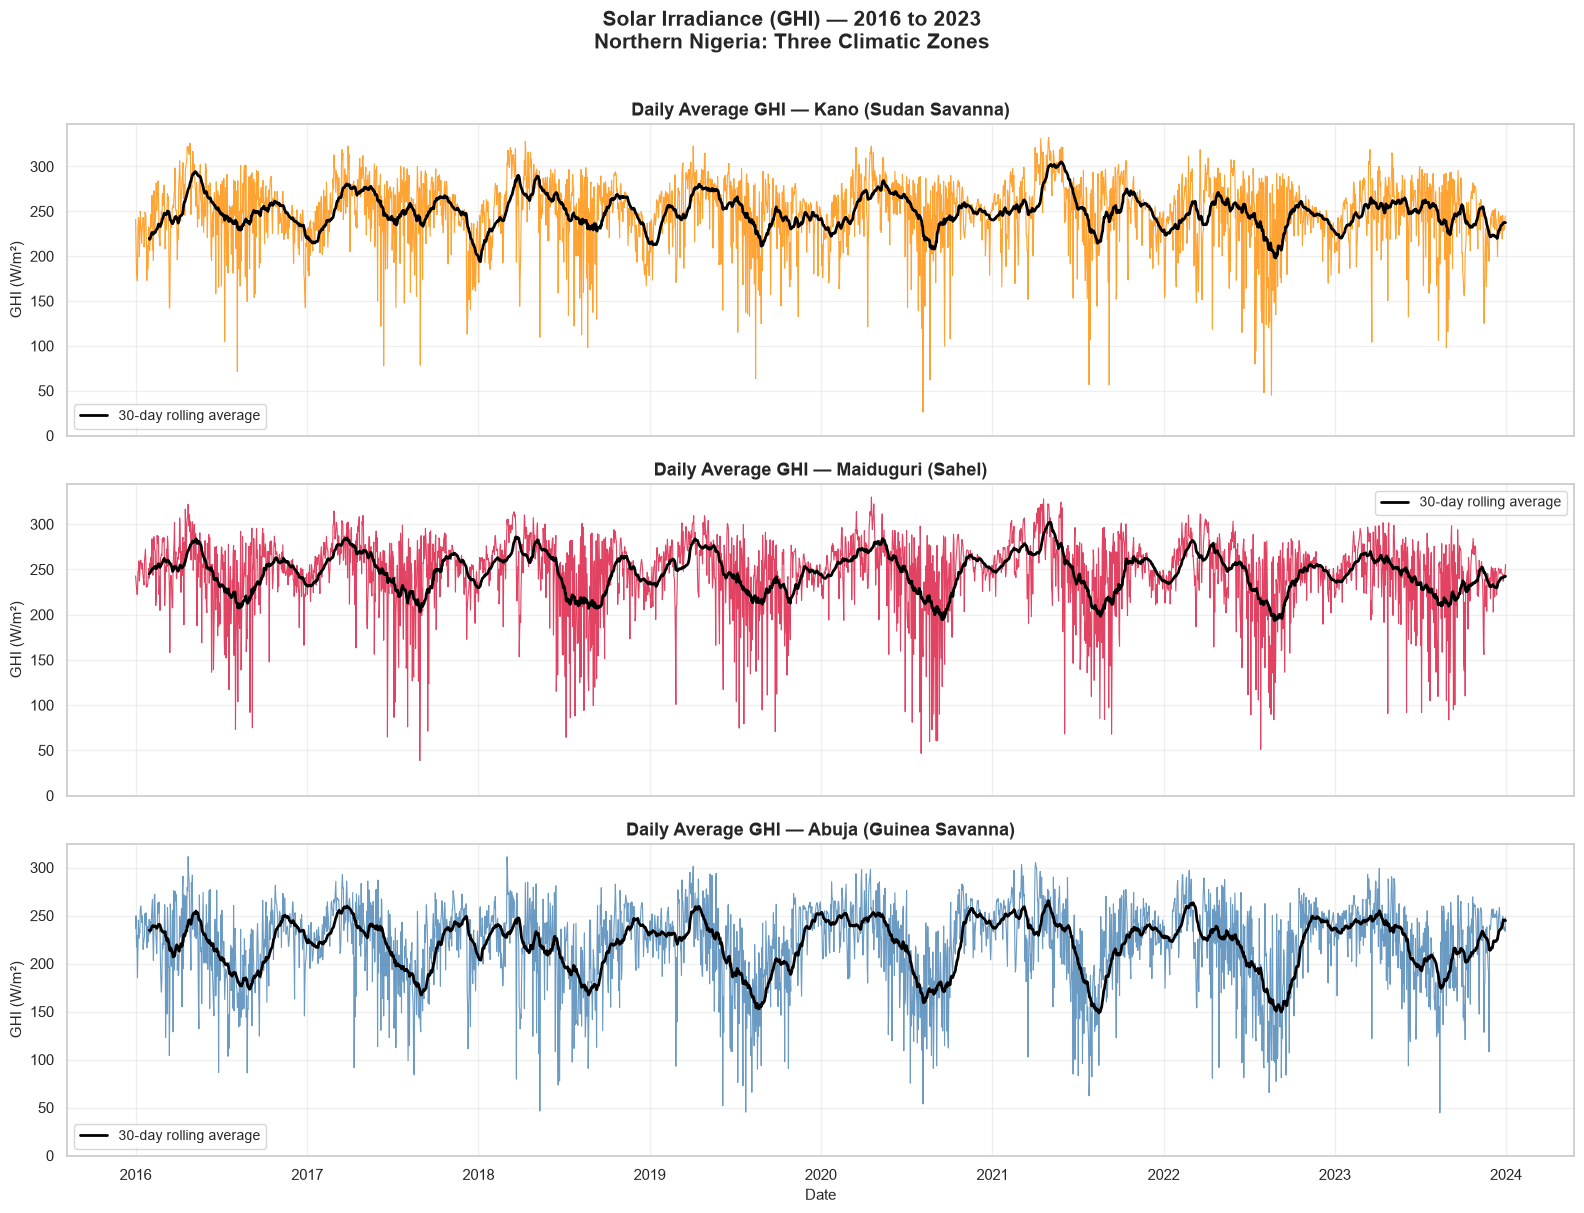


✅ Plot saved to: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\GHI_timeseries_all_cities.png


In [8]:
# ============================================================
# STAGE 2 - CELL 8: Visualise GHI Over Time — All Three Cities
# ============================================================

# We plot daily average GHI to see seasonal patterns clearly
# Plotting hourly data directly would produce 70,000+ points
# per city which would be an unreadable mess

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

cities_data = [
    (df_kano,      'Kano (Sudan Savanna)',      'darkorange'),
    (df_maiduguri, 'Maiduguri (Sahel)',          'crimson'),
    (df_abuja,     'Abuja (Guinea Savanna)',     'steelblue')
]

for ax, (df, label, color) in zip(axes, cities_data):
    
    # Resample to daily averages for a cleaner plot
    # 'D' means daily frequency
    daily_ghi = df['GHI'].resample('D').mean()
    
    ax.plot(daily_ghi.index, daily_ghi.values,
            color=color, linewidth=0.8, alpha=0.8)
    
    # Add a 30-day rolling average to show the trend clearly
    rolling_avg = daily_ghi.rolling(window=30).mean()
    ax.plot(rolling_avg.index, rolling_avg.values,
            color='black', linewidth=2,
            label='30-day rolling average')
    
    ax.set_title(f'Daily Average GHI — {label}',
                 fontsize=13, fontweight='bold')
    ax.set_ylabel('GHI (W/m²)', fontsize=11)
    ax.legend(fontsize=10)
    ax.set_ylim(0, None)

axes[-1].set_xlabel('Date', fontsize=11)
fig.suptitle('Solar Irradiance (GHI) — 2016 to 2023\n'
             'Northern Nigeria: Three Climatic Zones',
             fontsize=15, fontweight='bold', y=1.01)

plt.tight_layout()

# Save the plot to your plots folder
save_path = os.path.join(PLOTS_DIR, 'GHI_timeseries_all_cities.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\n✅ Plot saved to: {save_path}")

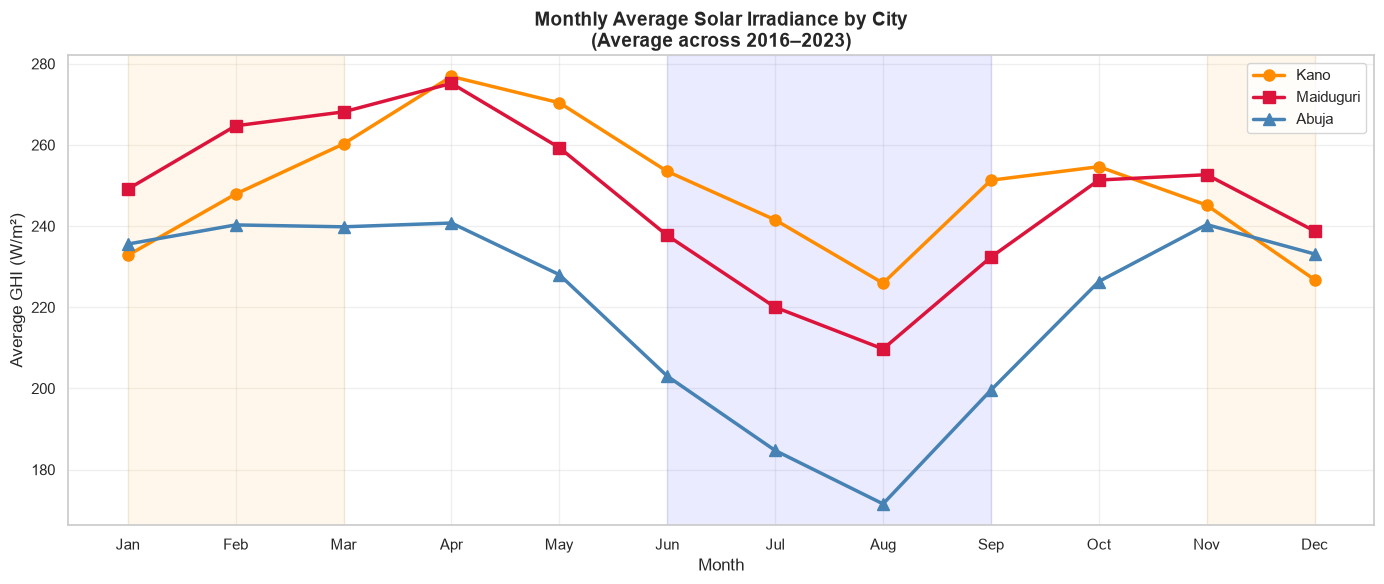

✅ Plot saved to: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Monthly_GHI_by_city.png


In [9]:
# ============================================================
# STAGE 2 - CELL 9: Monthly Average GHI — Seasonal Pattern
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

# Extract month from the datetime index
# and calculate average GHI per month across all 8 years

cities_data = [
    (df_kano,      'Kano',      'darkorange', 'o'),
    (df_maiduguri, 'Maiduguri', 'crimson',    's'),
    (df_abuja,     'Abuja',     'steelblue',  '^')
]

month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

for df, label, color, marker in cities_data:
    
    # Group by month number (1=Jan, 2=Feb etc)
    # and calculate the mean GHI for each month
    monthly = df.groupby(df.index.month)['GHI'].mean()
    
    ax.plot(monthly.index, monthly.values,
            color=color, marker=marker,
            linewidth=2.5, markersize=8, label=label)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Average GHI (W/m²)', fontsize=12)
ax.set_title('Monthly Average Solar Irradiance by City\n'
             '(Average across 2016–2023)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)

# Shade the harmattan season (Nov-Mar)
ax.axvspan(1, 3, alpha=0.08, color='orange',
           label='Harmattan period')
ax.axvspan(11, 12, alpha=0.08, color='orange')

# Shade the monsoon season (Jun-Sep)
ax.axvspan(6, 9, alpha=0.08, color='blue',
           label='Monsoon period')

plt.tight_layout()

save_path = os.path.join(PLOTS_DIR, 'Monthly_GHI_by_city.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot saved to: {save_path}")

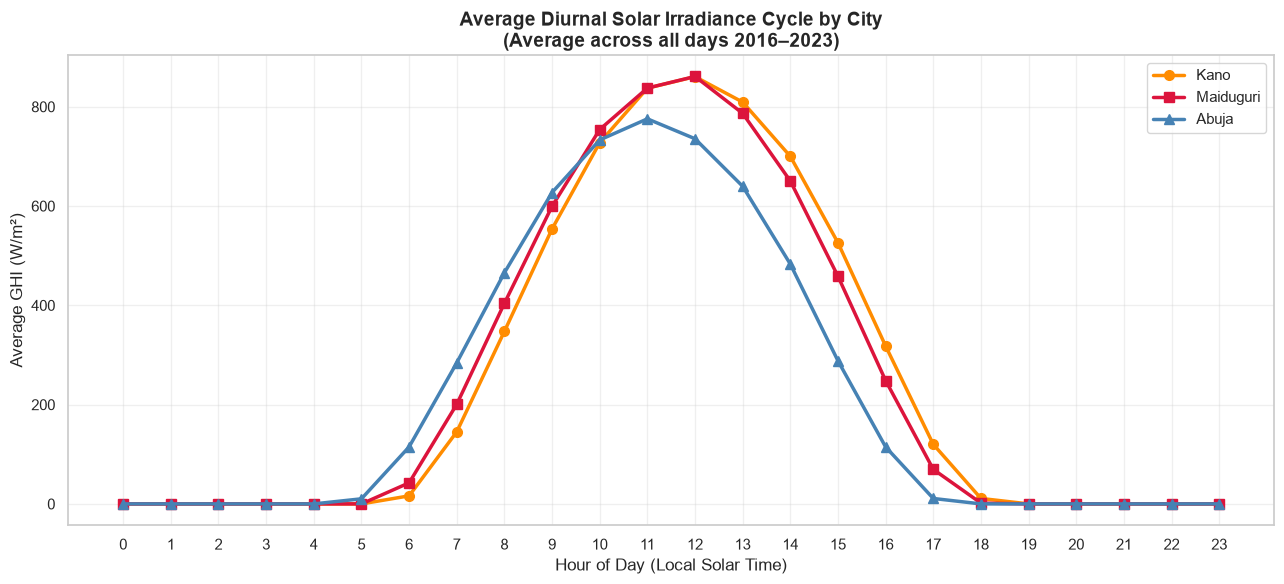

✅ Plot saved to: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Diurnal_GHI_by_city.png


In [10]:
# ============================================================
# STAGE 2 - CELL 10: Hourly Average GHI — Diurnal Cycle
# ============================================================

# The diurnal cycle shows the average pattern of solar
# irradiance across the 24 hours of a typical day
# This reveals sunrise time, peak irradiance hour, sunset time

fig, ax = plt.subplots(figsize=(13, 6))

cities_data = [
    (df_kano,      'Kano',      'darkorange', 'o'),
    (df_maiduguri, 'Maiduguri', 'crimson',    's'),
    (df_abuja,     'Abuja',     'steelblue',  '^')
]

for df, label, color, marker in cities_data:
    
    # Group by hour of day and calculate mean GHI
    hourly = df.groupby(df.index.hour)['GHI'].mean()
    
    ax.plot(hourly.index, hourly.values,
            color=color, marker=marker,
            linewidth=2.5, markersize=7, label=label)

ax.set_xticks(range(0, 24))
ax.set_xlabel('Hour of Day (Local Solar Time)', fontsize=12)
ax.set_ylabel('Average GHI (W/m²)', fontsize=12)
ax.set_title('Average Diurnal Solar Irradiance Cycle by City\n'
             '(Average across all days 2016–2023)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)

plt.tight_layout()
save_path = os.path.join(PLOTS_DIR, 'Diurnal_GHI_by_city.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot saved to: {save_path}")

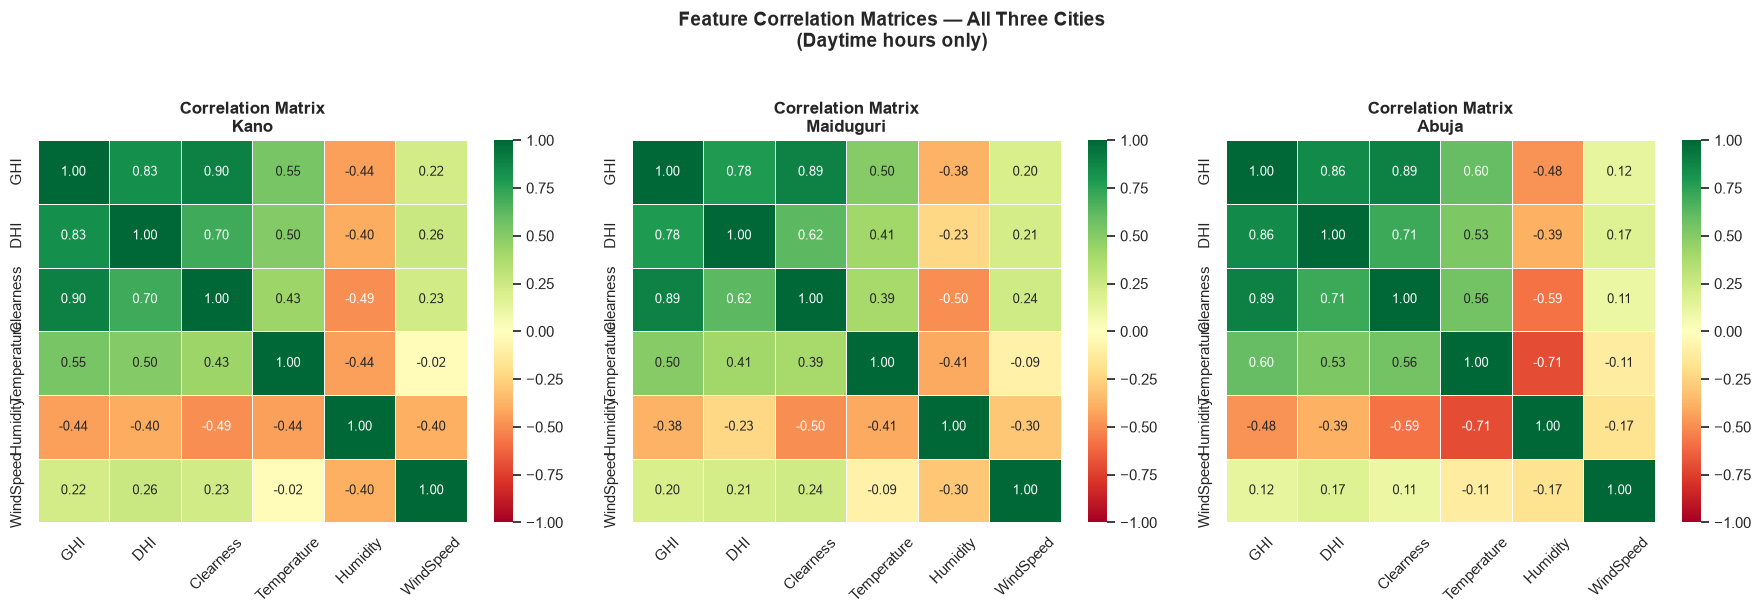

✅ Plot saved to: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Correlation_heatmaps.png


In [11]:
# ============================================================
# STAGE 2 - CELL 11: Correlation Heatmap
# ============================================================

# Correlation measures how strongly two variables move together
# Values range from -1 (perfect negative) to +1 (perfect positive)
# 0 means no linear relationship

# We analyse only daytime data because night-time zeros
# would distort the correlations artificially
# Daytime = hours where GHI > 0

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

cities_data = [
    (df_kano,      'Kano',      axes[0]),
    (df_maiduguri, 'Maiduguri', axes[1]),
    (df_abuja,     'Abuja',     axes[2])
]

feature_cols = ['GHI', 'DHI', 'Clearness',
                'Temperature', 'Humidity', 'WindSpeed']

for df, label, ax in cities_data:
    
    # Filter to daytime only
    df_day = df[df['GHI'] > 0][feature_cols]
    
    # Calculate correlation matrix
    corr_matrix = df_day.corr()
    
    # Plot as heatmap
    sns.heatmap(
        corr_matrix,
        ax=ax,
        annot=True,         # Show numbers inside cells
        fmt='.2f',          # 2 decimal places
        cmap='RdYlGn',      # Red=negative, Green=positive
        vmin=-1, vmax=1,    # Fix colour scale
        linewidths=0.5,
        annot_kws={'size': 9}
    )
    ax.set_title(f'Correlation Matrix\n{label}',
                 fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Feature Correlation Matrices — All Three Cities\n'
             '(Daytime hours only)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

save_path = os.path.join(PLOTS_DIR, 'Correlation_heatmaps.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot saved to: {save_path}")

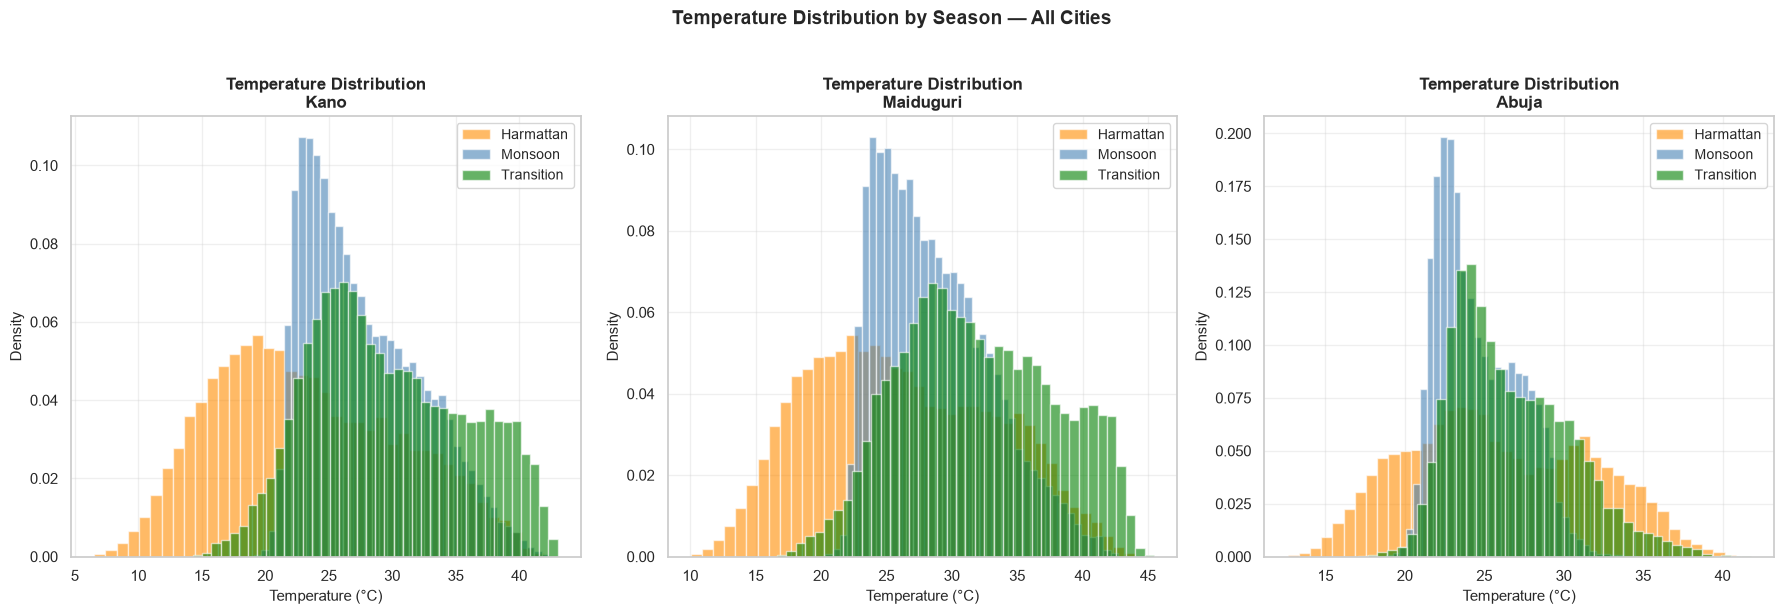

✅ Plot saved to: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Temperature_by_season.png


In [12]:
# ============================================================
# STAGE 2 - CELL 12: Temperature Distribution by Season
# ============================================================

# Define seasons based on Northern Nigerian climate
# Harmattan: November to March (dry, dusty, cooler nights)
# Monsoon  : June to September (wet, cloudy, humid)
# Transition: April-May and October

def assign_season(month):
    if month in [11, 12, 1, 2, 3]:
        return 'Harmattan'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Transition'

# Add Season column to each DataFrame
for df in [df_kano, df_maiduguri, df_abuja]:
    df['Season'] = df.index.month.map(assign_season)

# Plot temperature distributions by season for each city
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

cities_data = [
    (df_kano,      'Kano',      axes[0]),
    (df_maiduguri, 'Maiduguri', axes[1]),
    (df_abuja,     'Abuja',     axes[2])
]

season_colors = {
    'Harmattan' : 'darkorange',
    'Monsoon'   : 'steelblue',
    'Transition': 'green'
}

for df, label, ax in cities_data:
    for season, color in season_colors.items():
        data = df[df['Season'] == season]['Temperature']
        ax.hist(data, bins=40, alpha=0.6,
                color=color, label=season, density=True)
    
    ax.set_title(f'Temperature Distribution\n{label}',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Temperature (°C)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.legend(fontsize=10)

plt.suptitle('Temperature Distribution by Season — All Cities',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

save_path = os.path.join(PLOTS_DIR, 'Temperature_by_season.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot saved to: {save_path}")

In [13]:
# ============================================================
# STAGE 2 - CELL 13: Save Cleaned Individual City Datasets
# ============================================================

# Save each cleaned city dataset as a new CSV file
# in the results folder so we do not have to redo all
# the loading and cleaning every time we open the notebook

save_paths = {
    'Kano'     : os.path.join(RESULTS_DIR, 'kano_cleaned.csv'),
    'Maiduguri': os.path.join(RESULTS_DIR, 'maiduguri_cleaned.csv'),
    'Abuja'    : os.path.join(RESULTS_DIR, 'abuja_cleaned.csv')
}

df_kano.to_csv(save_paths['Kano'])
df_maiduguri.to_csv(save_paths['Maiduguri'])
df_abuja.to_csv(save_paths['Abuja'])

print("="*55)
print("CLEANED DATASETS SAVED")
print("="*55)
for city, path in save_paths.items():
    size_kb = os.path.getsize(path) / 1024
    print(f"✅ {city}: {path}")
    print(f"   Size: {size_kb:.1f} KB")

CLEANED DATASETS SAVED
✅ Kano: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\results\kano_cleaned.csv
   Size: 4617.6 KB
✅ Maiduguri: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\results\maiduguri_cleaned.csv
   Size: 4952.9 KB
✅ Abuja: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\results\abuja_cleaned.csv
   Size: 4687.9 KB


In [14]:
# ============================================================
# STAGE 2 - CELL 14: Stage 2 Completion Summary
# ============================================================

print("="*60)
print("STAGE 2 COMPLETE — DATA LOADING, EXPLORATION & CLEANING")
print("="*60)
print()
print("✅ All 24 NASA POWER CSV files loaded successfully")
print("✅ 8 yearly files combined per city into one dataset")
print("✅ Proper DateTime index created from YEAR/MO/DY/HR columns")
print("✅ Columns renamed to readable names")
print("   (ALLSKY_SFC_SW_DWN → GHI, T2M → Temperature etc.)")
print("✅ -999 missing values replaced with 0 (nighttime hours)")
print("✅ Data types verified — all columns numeric")
print("✅ Statistical summaries computed for all three cities")
print("✅ Season column added (Harmattan/Monsoon/Transition)")
print()
print("VISUALISATIONS PRODUCED AND SAVED:")
print("  📊 GHI time series — 2016 to 2023 all cities")
print("  📊 Monthly average GHI — seasonal pattern")
print("  📊 Diurnal cycle — average daily irradiance pattern")
print("  📊 Correlation heatmaps — all three cities")
print("  📊 Temperature distribution by season")
print()
print("CLEANED DATASETS SAVED:")
print(f"  💾 kano_cleaned.csv")
print(f"  💾 maiduguri_cleaned.csv")
print(f"  💾 abuja_cleaned.csv")
print()

# Final dataset sizes
for name, df in [('Kano', df_kano),
                  ('Maiduguri', df_maiduguri),
                  ('Abuja', df_abuja)]:
    print(f"{name}: {len(df):,} rows × "
          f"{df.shape[1]} columns | "
          f"{df.index[0].date()} → {df.index[-1].date()}")

print()
print("NEXT → Stage 3: Feature Engineering and Normalisation")
print("="*60)

STAGE 2 COMPLETE — DATA LOADING, EXPLORATION & CLEANING

✅ All 24 NASA POWER CSV files loaded successfully
✅ 8 yearly files combined per city into one dataset
✅ Proper DateTime index created from YEAR/MO/DY/HR columns
✅ Columns renamed to readable names
   (ALLSKY_SFC_SW_DWN → GHI, T2M → Temperature etc.)
✅ -999 missing values replaced with 0 (nighttime hours)
✅ Data types verified — all columns numeric
✅ Statistical summaries computed for all three cities
✅ Season column added (Harmattan/Monsoon/Transition)

VISUALISATIONS PRODUCED AND SAVED:
  📊 GHI time series — 2016 to 2023 all cities
  📊 Monthly average GHI — seasonal pattern
  📊 Diurnal cycle — average daily irradiance pattern
  📊 Correlation heatmaps — all three cities
  📊 Temperature distribution by season

CLEANED DATASETS SAVED:
  💾 kano_cleaned.csv
  💾 maiduguri_cleaned.csv
  💾 abuja_cleaned.csv

Kano: 70,128 rows × 8 columns | 2016-01-01 → 2023-12-31
Maiduguri: 70,128 rows × 8 columns | 2016-01-01 → 2023-12-31
Abuja: 70,128

In [15]:
# Confirm saved files are readable
import pandas as pd
import os

RESULTS_DIR = "C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project/results"

for city in ['kano', 'maiduguri', 'abuja']:
    path = os.path.join(RESULTS_DIR, f'{city}_cleaned.csv')
    df   = pd.read_csv(path, index_col='Datetime',
                       parse_dates=True)
    print(f"✅ {city}_cleaned.csv loaded — "
          f"{len(df):,} rows × {df.shape[1]} columns")
    print(f"   Columns: {list(df.columns)}\n")

✅ kano_cleaned.csv loaded — 70,128 rows × 8 columns
   Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City', 'Season']

✅ maiduguri_cleaned.csv loaded — 70,128 rows × 8 columns
   Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City', 'Season']

✅ abuja_cleaned.csv loaded — 70,128 rows × 8 columns
   Columns: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'City', 'Season']

